# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [149]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

# TODO: imports (pandas, matplotlib, seaborn, ...)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [150]:
mares_csv = "mares_2025.csv"
previsao_csv = "mares_previsao.csv"
ondas_csv = "ondas.csv"
vento_csv = "vento.csv"

df_mares = pd.read_csv(DIR_RAW / mares_csv)
df_previsao = pd.read_csv(DIR_RAW / previsao_csv)
df_ondas = pd.read_csv(DIR_RAW / ondas_csv)
df_vento = pd.read_csv(DIR_RAW / vento_csv)

In [151]:
print("DataFrames carregados com sucesso:")
print(f"- {mares_csv}: {df_mares.shape[0]} linhas, {df_mares.shape[1]} colunas")
print(f"- {previsao_csv}: {df_previsao.shape[0]} linhas, {df_previsao.shape[1]} colunas")
print(f"- {ondas_csv}: {df_ondas.shape[0]} linhas, {df_ondas.shape[1]} colunas")
print(f"- {vento_csv}: {df_vento.shape[0]} linhas, {df_vento.shape[1]} colunas")

DataFrames carregados com sucesso:
- mares_2025.csv: 1410 linhas, 9 colunas
- mares_previsao.csv: 120 linhas, 9 colunas
- ondas.csv: 168 linhas, 6 colunas
- vento.csv: 168 linhas, 6 colunas


In [152]:
df_mares.sample(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol
983,2025,9,12,13:05,0.5,baixa,71,5:12,17:17
910,2025,8,24,16:47,2.4,alta,91,5:22,17:20
53,2025,1,14,23:42,0.3,baixa,83,5:12,17:44
1390,2025,12,26,21:27,2.1,alta,58,5:02,17:37
529,2025,5,18,1:14,0.7,baixa,47,5:21,17:10


In [153]:
df_mares.info()

<class 'pandas.DataFrame'>
RangeIndex: 1410 entries, 0 to 1409
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ano          1410 non-null   int64  
 1   mes          1410 non-null   int64  
 2   dia          1410 non-null   int64  
 3   hora         1410 non-null   str    
 4   altura       1410 non-null   float64
 5   tipo         1410 non-null   str    
 6   coeficiente  1410 non-null   int64  
 7   nascer_sol   1410 non-null   str    
 8   por_sol      1410 non-null   str    
dtypes: float64(1), int64(4), str(4)
memory usage: 99.3 KB


In [154]:
df_mares.isna().sum()

ano            0
mes            0
dia            0
hora           0
altura         0
tipo           0
coeficiente    0
nascer_sol     0
por_sol        0
dtype: int64

In [155]:
df_mares.duplicated().sum()

np.int64(0)

In [156]:
df_previsao.sample(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol
24,2026,10,7,7:44,0.4,baixa,81,4:59,17:14
114,2026,10,30,13:48,0.6,baixa,64,4:51,17:14
5,2026,10,2,7:39,2.1,alta,50,5:02,17:14
105,2026,10,28,6:01,2.6,alta,89,4:51,17:14
95,2026,10,25,16:13,2.5,alta,99,4:52,17:14


In [157]:
df_previsao.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ano          120 non-null    int64  
 1   mes          120 non-null    int64  
 2   dia          120 non-null    int64  
 3   hora         120 non-null    str    
 4   altura       120 non-null    float64
 5   tipo         120 non-null    str    
 6   coeficiente  120 non-null    int64  
 7   nascer_sol   120 non-null    str    
 8   por_sol      120 non-null    str    
dtypes: float64(1), int64(4), str(4)
memory usage: 8.6 KB


In [158]:
df_previsao.isna().sum()

ano            0
mes            0
dia            0
hora           0
altura         0
tipo           0
coeficiente    0
nascer_sol     0
por_sol        0
dtype: int64

In [159]:
df_previsao.duplicated().sum()

np.int64(0)

In [160]:
df_ondas.sample(5)

,ano,mes,dia,hora,direcao,altura_onda_m
109,2026,10,15,13:00,E,1.3
161,2026,10,17,17:00,E,1.2
6,2026,10,11,6:00,ESE,0.9
45,2026,10,12,21:00,E,1.2
76,2026,10,14,4:00,E,1.3


In [161]:
df_ondas.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ano            168 non-null    int64  
 1   mes            168 non-null    int64  
 2   dia            168 non-null    int64  
 3   hora           168 non-null    str    
 4   direcao        168 non-null    str    
 5   altura_onda_m  168 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 8.0 KB


In [162]:
df_ondas.isna().sum()

ano              0
mes              0
dia              0
hora             0
direcao          0
altura_onda_m    0
dtype: int64

In [163]:
df_ondas.duplicated().sum()

np.int64(0)

In [164]:
df_vento.sample(5)

,ano,mes,dia,hora,direcao,velocidade_vento_kmh
138,2026,10,16,18:00,ENE,23.0
96,2026,10,15,0:00,E,22.0
120,2026,10,16,0:00,ENE,26.0
153,2026,10,17,9:00,ENE,19.0
129,2026,10,16,9:00,ENE,22.0


In [165]:
df_vento.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ano                   168 non-null    int64  
 1   mes                   168 non-null    int64  
 2   dia                   168 non-null    int64  
 3   hora                  168 non-null    str    
 4   direcao               168 non-null    str    
 5   velocidade_vento_kmh  168 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 8.0 KB


In [166]:
df_vento.isna().sum()

ano                     0
mes                     0
dia                     0
hora                    0
direcao                 0
velocidade_vento_kmh    0
dtype: int64

In [167]:
df_vento.duplicated().sum()

np.int64(0)

**Conclusões da seção 1**

| Tabela | Linhas | Colunas | Conta |
|---|---|---|---|
| `mares_2025` | 1410 | 9 | 365 dias × ~3,9 marés/dia |
| `mares_previsao` | 120 | 9 | 31 dias (outubro/2026) × ~3,9 marés/dia |
| `ondas` | 168 | 6 | 7 dias × 24 horas |
| `vento` | 168 | 6 | 7 dias × 24 horas |

- **Número de linhas:** os tamanhos fazem sentido. As duas tabelas de maré ficam abaixo de 4 eventos por dia (365 × 4 = 1460 e 31 × 4 = 124) porque o intervalo entre marés é de cerca de 6h12 e, por isso, alguns dias têm só 3 eventos. As tabelas de ondas e vento têm exatamente 24 leituras por dia, nos 7 dias da previsão.
- **Tipos:** `altura`, `altura_onda_m` e `velocidade_vento_kmh` já chegaram como `float64`, então a vírgula decimal foi resolvida na coleta. `hora`, `nascer_sol` e `por_sol` vieram como texto, e a data está dividida em três colunas inteiras (`ano`, `mes`, `dia`). Isso será tratado na limpeza. `direcao` (vento e onda) é categórica, em texto.
- **Nulos e duplicatas:** nenhuma das quatro tabelas tem valores nulos nem linhas duplicadas.
- **Cobertura:** a tábua de 2025 cobre vários meses do ano. As previsões de ondas e vento cobrem só outubro de 2026, então não têm datas em comum com a tábua de 2025.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [168]:
def montar_datetime(df):
    datas = pd.to_datetime(
        df[["ano", "mes", "dia"]].rename(
            columns={"ano": "year", "mes": "month", "dia": "day"}
        )
    )
    horas = pd.to_timedelta(df["hora"] + ":00")  
    return datas + horas


tabelas = {
    "mares_2025": df_mares,
    "mares_previsao": df_previsao,
    "ondas": df_ondas,
    "vento": df_vento,
}

for nome, df in tabelas.items():
    df["datetime"] = montar_datetime(df)
    df.sort_values("datetime", inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"--- {nome}")
    print("dtype:", df["datetime"].dtype)
    print("de", df["datetime"].min(), "até", df["datetime"].max())
    print("ordenada:", df["datetime"].is_monotonic_increasing)

--- mares_2025
dtype: datetime64[us]
de 2025-01-01 05:50:00 até 2025-12-31 20:38:00
ordenada: True
--- mares_previsao
dtype: datetime64[us]
de 2026-10-01 00:24:00 até 2026-10-31 20:58:00
ordenada: True
--- ondas
dtype: datetime64[us]
de 2026-10-11 00:00:00 até 2026-10-17 23:00:00
ordenada: True
--- vento
dtype: datetime64[us]
de 2026-10-11 00:00:00 até 2026-10-17 23:00:00
ordenada: True


In [169]:
df_mares.head(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol,datetime
0,2025,1,1,5:50,2.4,alta,81,5:06,17:39,2025-01-01 05:50:00
1,2025,1,1,12:00,0.4,baixa,81,5:06,17:39,2025-01-01 12:00:00
2,2025,1,1,18:07,2.3,alta,81,5:06,17:39,2025-01-01 18:07:00
3,2025,1,2,0:19,0.4,baixa,80,5:06,17:40,2025-01-02 00:19:00
4,2025,1,2,6:31,2.4,alta,80,5:06,17:40,2025-01-02 06:31:00


In [170]:
df_previsao.head(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol,datetime
0,2026,10,1,0:24,0.4,baixa,64,5:02,17:15,2026-10-01 00:24:00
1,2026,10,1,6:45,2.3,alta,64,5:02,17:15,2026-10-01 06:45:00
2,2026,10,1,12:54,0.6,baixa,64,5:02,17:15,2026-10-01 12:54:00
3,2026,10,1,18:57,2.1,alta,64,5:02,17:15,2026-10-01 18:57:00
4,2026,10,2,1:14,0.5,baixa,50,5:02,17:14,2026-10-02 01:14:00


In [171]:
df_ondas.head(5)

,ano,mes,dia,hora,direcao,altura_onda_m,datetime
0,2026,10,11,0:00,ESE,1.0,2026-10-11 00:00:00
1,2026,10,11,1:00,ESE,1.0,2026-10-11 01:00:00
2,2026,10,11,2:00,ESE,1.0,2026-10-11 02:00:00
3,2026,10,11,3:00,ESE,1.0,2026-10-11 03:00:00
4,2026,10,11,4:00,ESE,1.0,2026-10-11 04:00:00


In [172]:
df_vento.head(5)

,ano,mes,dia,hora,direcao,velocidade_vento_kmh,datetime
0,2026,10,11,0:00,SE,21.0,2026-10-11 00:00:00
1,2026,10,11,1:00,SE,22.0,2026-10-11 01:00:00
2,2026,10,11,2:00,SE,20.0,2026-10-11 02:00:00
3,2026,10,11,3:00,ESE,17.0,2026-10-11 03:00:00
4,2026,10,11,4:00,ESE,21.0,2026-10-11 04:00:00


**Conclusões da seção 2**

- **Data e hora:** `ano`, `mes`, `dia` e `hora` (texto, sem zero à esquerda) foram combinados numa coluna única `datetime` em cada uma das quatro tabelas, que depois foram ordenadas por ela. 
- **Intervalos conferidos:** `mares_2025` cobre 2025 inteiro; `mares_previsao` cobre outubro de 2026; `ondas` e `vento` cobrem os mesmos 7 dias (11 a 17 de outubro de 2026).
- **Decimais:** nada a fazer. A vírgula decimal já foi tratada na coleta, e as colunas numéricas chegaram como `float64`.
- **Nulos e duplicatas:** nenhum encontrado nas quatro tabelas, então nenhuma linha foi descartada ou preenchida.
- **Colunas originais:** a limpeza foi feita no lugar, e as colunas originais (`ano`, `mes`, `dia` e `hora`) foram mantidas.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

In [173]:
PRAIA = {
    "azul": "#1E88C8",
    "azul_escuro": "#1B4F8A",
    "azul_claro": "#7FC8E8",
    "amarelo": "#FFC93C",
    "laranja": "#F28C28",
    "coral": "#E8604C",
    "areia": "#F2D7A6",
}

sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#FFFBF2"})

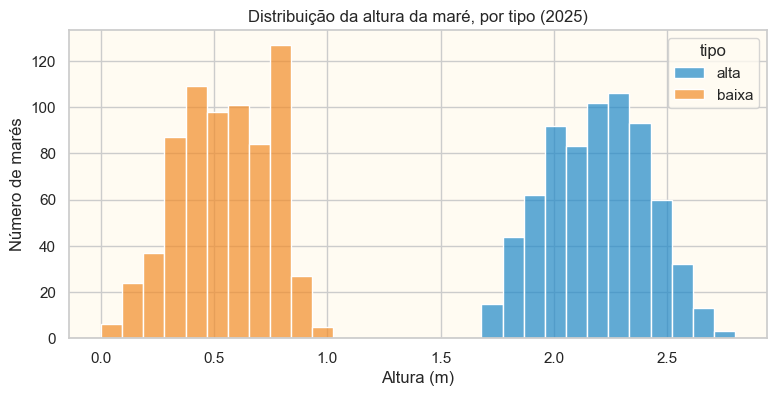

In [174]:
plt.figure(figsize=(9, 4))
sns.histplot(
    data=df_mares, x="altura", hue="tipo", bins=30,
    palette={"alta": PRAIA["azul"], "baixa": PRAIA["laranja"]}, alpha=0.7,
)
plt.title("Distribuição da altura da maré, por tipo (2025)")
plt.xlabel("Altura (m)")
plt.ylabel("Número de marés")
plt.show()

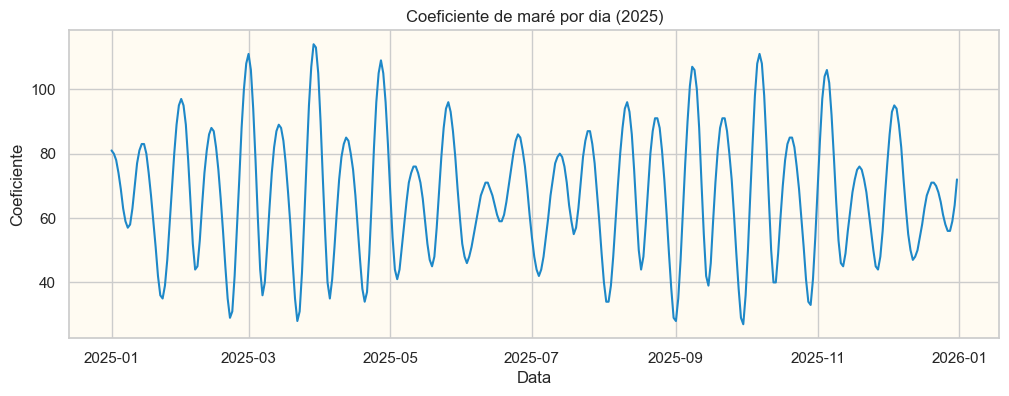

In [175]:
diario = df_mares.drop_duplicates(subset=["ano", "mes", "dia"]).copy()
diario["data"] = diario["datetime"].dt.normalize()

plt.figure(figsize=(12, 4))
sns.lineplot(data=diario, x="data", y="coeficiente", color=PRAIA["azul"])
plt.title("Coeficiente de maré por dia (2025)")
plt.xlabel("Data")
plt.ylabel("Coeficiente")
plt.show()

count    168.000000
mean       1.218452
std        0.110329
min        0.900000
25%        1.200000
50%        1.200000
75%        1.300000
max        1.400000
Name: altura_onda_m, dtype: float64


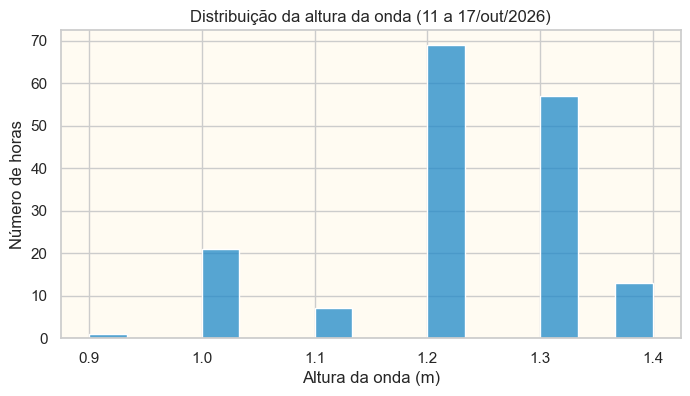

In [176]:
print(df_ondas["altura_onda_m"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df_ondas["altura_onda_m"], bins=15, color=PRAIA["azul"])
plt.title("Distribuição da altura da onda (11 a 17/out/2026)")
plt.xlabel("Altura da onda (m)")
plt.ylabel("Número de horas")
plt.show()

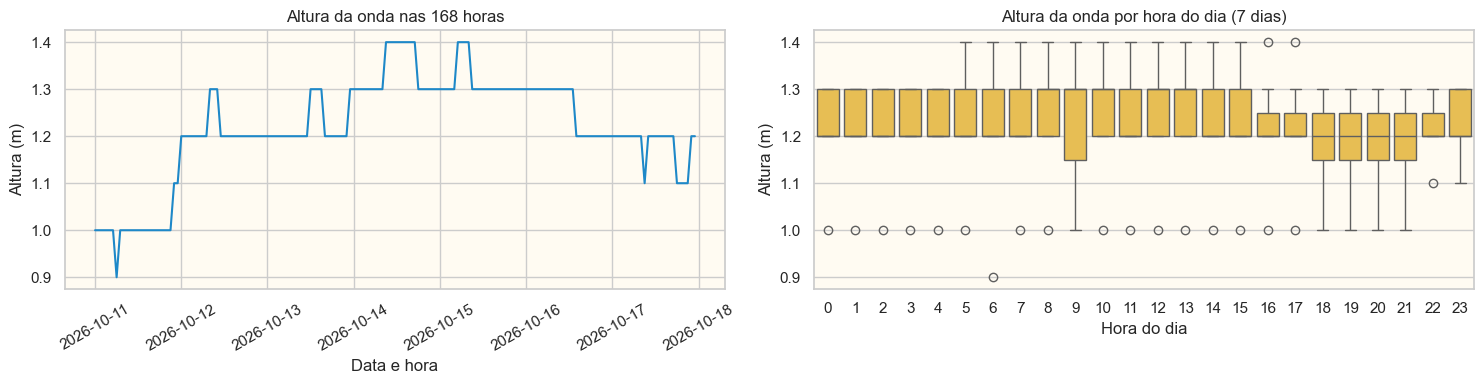

In [177]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.lineplot(data=df_ondas, x="datetime", y="altura_onda_m",
             color=PRAIA["azul"], ax=axes[0])
axes[0].set_title("Altura da onda nas 168 horas")
axes[0].set_xlabel("Data e hora")
axes[0].set_ylabel("Altura (m)")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(x=df_ondas["datetime"].dt.hour, y=df_ondas["altura_onda_m"],
            color=PRAIA["amarelo"], ax=axes[1])
axes[1].set_title("Altura da onda por hora do dia (7 dias)")
axes[1].set_xlabel("Hora do dia")
axes[1].set_ylabel("Altura (m)")

plt.tight_layout()
plt.show()

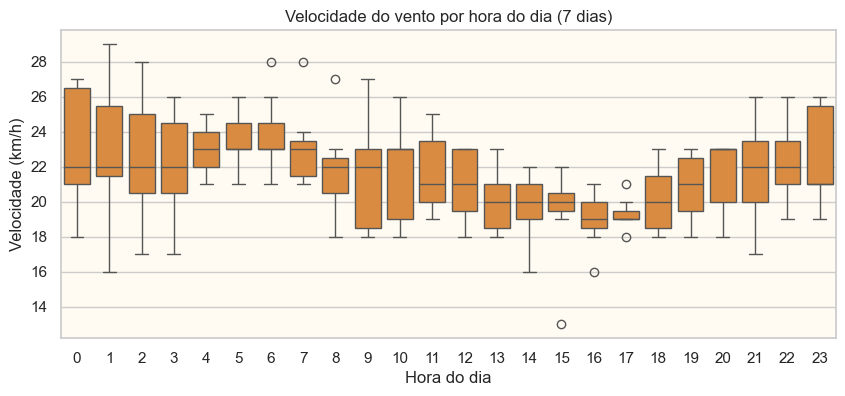

In [178]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_vento["datetime"].dt.hour, y=df_vento["velocidade_vento_kmh"],
            color=PRAIA["laranja"])
plt.title("Velocidade do vento por hora do dia (7 dias)")
plt.xlabel("Hora do dia")
plt.ylabel("Velocidade (km/h)")
plt.show()

<StringArray>
['SE', 'ESE', 'E', 'ENE']
Length: 4, dtype: str


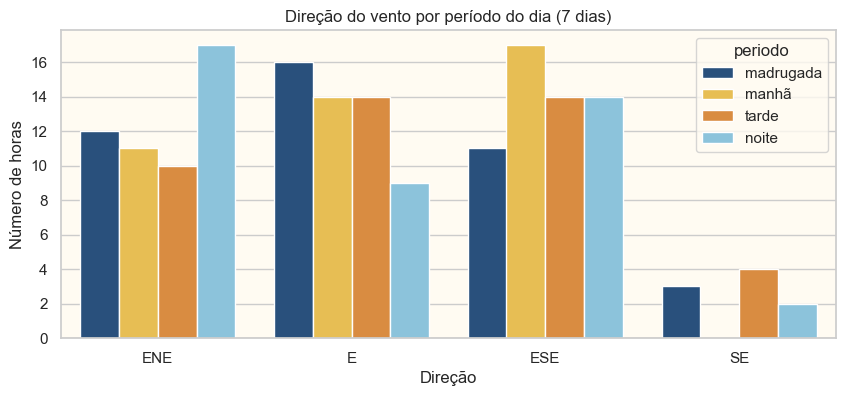

In [ ]:
print(df_vento["direcao"].unique())  

periodos = ["madrugada", "manhã", "tarde", "noite"]
vento_p = df_vento.assign(
    periodo=pd.cut(df_vento["datetime"].dt.hour,
                   bins=[-1, 5, 11, 17, 23], labels=periodos)
)

bussola = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
ordem = [d for d in bussola if d in vento_p["direcao"].unique()]

plt.figure(figsize=(10, 4))
sns.countplot(
    data=vento_p, x="direcao", hue="periodo", order=ordem, hue_order=periodos,
    palette=dict(zip(periodos, [PRAIA["azul_escuro"], PRAIA["amarelo"],
                                PRAIA["laranja"], PRAIA["azul_claro"]])),
)
plt.title("Direção do vento por período do dia (7 dias)")
plt.xlabel("Direção")
plt.ylabel("Número de horas")
plt.show()

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?